# 08.08 — Brick 8: Narrative Structure and Success Signals

This notebook is **only Brick 8**.

It answers one final results question:

> How do narrative-network structures relate to different success signals?

Correct thesis framing:

```text
plot-network structure is descriptively associated with different success signals
```

Do **not** frame this as a prediction thesis or causal proof.

## Outputs

Figures are saved to:

```text
outputs/thesis_bricks/08_structure_success/figures/
```

Main figures:

1. `01_structure_success_question_map.png`
2. `02_success_model_summary.png`
3. `03_model_improvement_by_success_dimension.png`
4. `04_community_success_profile_heatmap.png`
5. `05_top_communities_by_evaluative_success.png`
6. `06_top_communities_by_commercial_success.png`
7. `07_centrality_success_profile.png`
8. `08_bridging_success_profile.png`
9. `09_key_result_interpretation_cards.png`
10. `10_final_results_storyline.png`


## 0. Setup

In [1]:

import os, re, math, textwrap, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.patheffects as pe

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 240)
pd.set_option("display.max_colwidth", 260)

COL = {
    "ink":"#222222","muted":"#62666D","grid":"#E4E7EB","panel":"#F7F8FA",
    "blue":"#2F6FB3","orange":"#D06C45","green":"#2F8F5B","purple":"#7A5BC2",
    "red":"#C94C4C","light_blue":"#E8F1FB","light_orange":"#FBEADF",
    "light_green":"#E6F4EC","light_purple":"#EFEAFB","light_gray":"#F2F4F7"
}
COMM_COLORS = ["#4E79A7","#F28E2B","#59A14F","#E15759","#76B7B2","#9C755F",
               "#EDC948","#B07AA1","#FF9DA7","#BAB0AC","#2F6FB3","#D06C45",
               "#2F8F5B","#7A5BC2","#C94C4C","#D9A21B","#5C6BC0","#26A69A",
               "#AB47BC","#8D6E63","#78909C","#EC407A","#43A047","#FB8C00",
               "#6D4C41","#00ACC1"]

plt.rcParams.update({
    "figure.facecolor":"white","axes.facecolor":"white","font.family":"DejaVu Sans",
    "font.size":12,"axes.titlesize":18,"axes.titleweight":"bold",
    "savefig.dpi":320,"figure.dpi":130
})

def save_fig(fig, name, dpi=320):
    png = FIG_DIR / name
    svg = FIG_DIR / name.replace(".png", ".svg")
    fig.savefig(png, dpi=dpi, bbox_inches="tight", facecolor="white")
    fig.savefig(svg, bbox_inches="tight", facecolor="white")
    print("Saved:", png)
    print("Saved:", svg)

def save_table(df, name):
    path = TABLE_DIR / name
    df.to_csv(path, index=False, encoding="utf-8")
    print("Saved:", path)
    return path

def write_text(txt, name):
    path = TEXT_DIR / name
    path.write_text(txt, encoding="utf-8")
    print("Saved:", path)
    return path

def safe_read(path):
    path = Path(path)
    return pd.read_csv(path) if path.exists() else None

def wrap_text(s, width=42):
    if pd.isna(s): return ""
    return "\n".join(textwrap.wrap(str(s), width=width))

def shorten(s, width=90):
    if pd.isna(s): return ""
    return textwrap.shorten(str(s).replace("\n"," "), width=width, placeholder="...")

def title_block(fig, title, subtitle=None, x=.05, y=.965):
    fig.text(x, y, title, ha="left", va="top", fontsize=22, fontweight="bold", color=COL["ink"])
    if subtitle:
        fig.text(x, y-.055, subtitle, ha="left", va="top", fontsize=12.5, color=COL["muted"])

def community_color(cid):
    try: return COMM_COLORS[int(cid) % len(COMM_COLORS)]
    except Exception: return COL["blue"]

def first_col(df, names):
    if df is None: return None
    for c in names:
        if c in df.columns: return c
    return None

def zscore(s):
    s = pd.to_numeric(s, errors="coerce")
    sd = s.std(skipna=True)
    if pd.isna(sd) or sd == 0: return s * np.nan
    return (s - s.mean(skipna=True)) / sd

def fmt_float(x, d=3):
    try: return f"{float(x):.{d}f}"
    except Exception: return "—"

def fmt_int(x):
    try: return f"{int(round(float(x))):,}"
    except Exception: return "—"


## 1. Paths and data loading

In [2]:

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped or failed:", e)

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()
PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
PROCESSED_FEATURES_DIR = PROJECT_DIR / "processed" / "features"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"

FINAL_DIR = PROJECT_DIR / "outputs" / "thesis_bricks" / "08_structure_success"
FIG_DIR = FINAL_DIR / "figures"
TABLE_DIR = FINAL_DIR / "tables"
TEXT_DIR = FINAL_DIR / "text"
for d in [FINAL_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

FILES = {
    "modeling": PROCESSED_FEATURES_DIR / "modeling_table_success_star_power.csv",
    "nodes": PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv",
    "community_labels": OUTPUT_TABLES_DIR / "community_manual_labeling_template_labeled.csv",
    "model_summary": OUTPUT_TABLES_DIR / "final_story_tables" / "final_model_summary_table.csv",
    "community_success": OUTPUT_TABLES_DIR / "final_story_tables" / "final_community_success_summary.csv",
    "community_outcome": OUTPUT_TABLES_DIR / "community_outcome_summary_descriptive.csv",
}
for k,p in FILES.items():
    print(f"{k:22s}", p.exists(), "-", p)

modeling = safe_read(FILES["modeling"])
nodes = safe_read(FILES["nodes"])
community_labels = safe_read(FILES["community_labels"])
model_summary = safe_read(FILES["model_summary"])
community_success = safe_read(FILES["community_success"])
community_outcome = safe_read(FILES["community_outcome"])

if modeling is None:
    modeling = nodes.copy()
if community_success is None:
    community_success = community_outcome.copy() if community_outcome is not None else None

# add labels
if community_labels is not None and "community_id" in modeling.columns:
    label_col = "suggested_label_manual" if "suggested_label_manual" in community_labels.columns else "narrative_label"
    lab = community_labels[["community_id", label_col, "n_films"]].drop_duplicates().rename(columns={label_col:"narrative_label"})
    if "narrative_label" not in modeling.columns:
        modeling = modeling.merge(lab[["community_id","narrative_label"]], on="community_id", how="left")
    if community_success is not None and "community_id" in community_success.columns and "narrative_label" not in community_success.columns:
        community_success = community_success.merge(lab, on="community_id", how="left")

print("modeling:", modeling.shape)
print("model_summary:", None if model_summary is None else model_summary.shape)
print("community_success:", None if community_success is None else community_success.shape)


Mounted at /content/drive
modeling               True - /content/drive/MyDrive/thesis_movie_project/processed/features/modeling_table_success_star_power.csv
nodes                  True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_nodes_lcc.csv
community_labels       True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_manual_labeling_template_labeled.csv
model_summary          True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_model_summary_table.csv
community_success      True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_community_success_summary.csv
community_outcome      True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_outcome_summary_descriptive.csv
modeling: (19202, 62)
model_summary: (4, 8)
community_success: (26, 11)


## 2. Prepare columns

In [3]:

df = modeling.copy()
title_col = "title" if "title" in df.columns else df.columns[0]

rev_raw = first_col(df, ["revenue_clean","revenue"])
rev_log = first_col(df, ["log_revenue","log_revenue_clean"])
if rev_log is None and rev_raw is not None:
    df["log_revenue"] = np.log1p(pd.to_numeric(df[rev_raw], errors="coerce").clip(lower=0))
    rev_log = "log_revenue"

rev_pct = first_col(df, ["revenue_percentile_year","revenue_percentile","revenue_pct_year"])
vote_avg = first_col(df, ["vote_average","rating","imdb_rating"])
pop = first_col(df, ["log_popularity","popularity"])
vote_count = first_col(df, ["vote_count","num_votes"])

if pop == "popularity":
    df["log_popularity"] = np.log1p(pd.to_numeric(df["popularity"], errors="coerce").clip(lower=0))
    pop = "log_popularity"
if pop is None and vote_count is not None:
    df["log_vote_count"] = np.log1p(pd.to_numeric(df[vote_count], errors="coerce").clip(lower=0))
    pop = "log_vote_count"

weighted_degree = first_col(df, ["weighted_degree","weighted_degree_from_edges"])
betweenness = first_col(df, ["betweenness_centrality_sampled","betweenness","betweenness_centrality"])

if weighted_degree:
    df["centrality_percentile"] = pd.to_numeric(df[weighted_degree], errors="coerce").rank(pct=True)
if betweenness:
    df["bridging_percentile"] = pd.to_numeric(df[betweenness], errors="coerce").rank(pct=True)

outcomes = []
if vote_avg: outcomes.append(("Evaluative reception", vote_avg, COL["green"]))
if rev_log: outcomes.append(("Commercial performance", rev_log, COL["orange"]))
if rev_pct: outcomes.append(("Commercial rank", rev_pct, COL["red"]))
if pop: outcomes.append(("Audience attention", pop, COL["blue"]))

detected = pd.DataFrame({
    "type": ["vote average","log revenue","revenue percentile","attention","centrality","bridging"],
    "column": [vote_avg, rev_log, rev_pct, pop, weighted_degree, betweenness]
})
save_table(detected, "00_detected_structure_success_columns.csv")
save_table(df, "00_prepared_structure_success_table.csv")
display(detected)


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/tables/00_detected_structure_success_columns.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/tables/00_prepared_structure_success_table.csv


,type,column
0,vote average,vote_average
1,log revenue,log_revenue
2,revenue percentile,revenue_percentile_year
3,attention,log_popularity
4,centrality,weighted_degree
5,bridging,betweenness_centrality_sampled


## 3. Figure 1 — Structure-success question map

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/01_structure_success_question_map.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/01_structure_success_question_map.svg


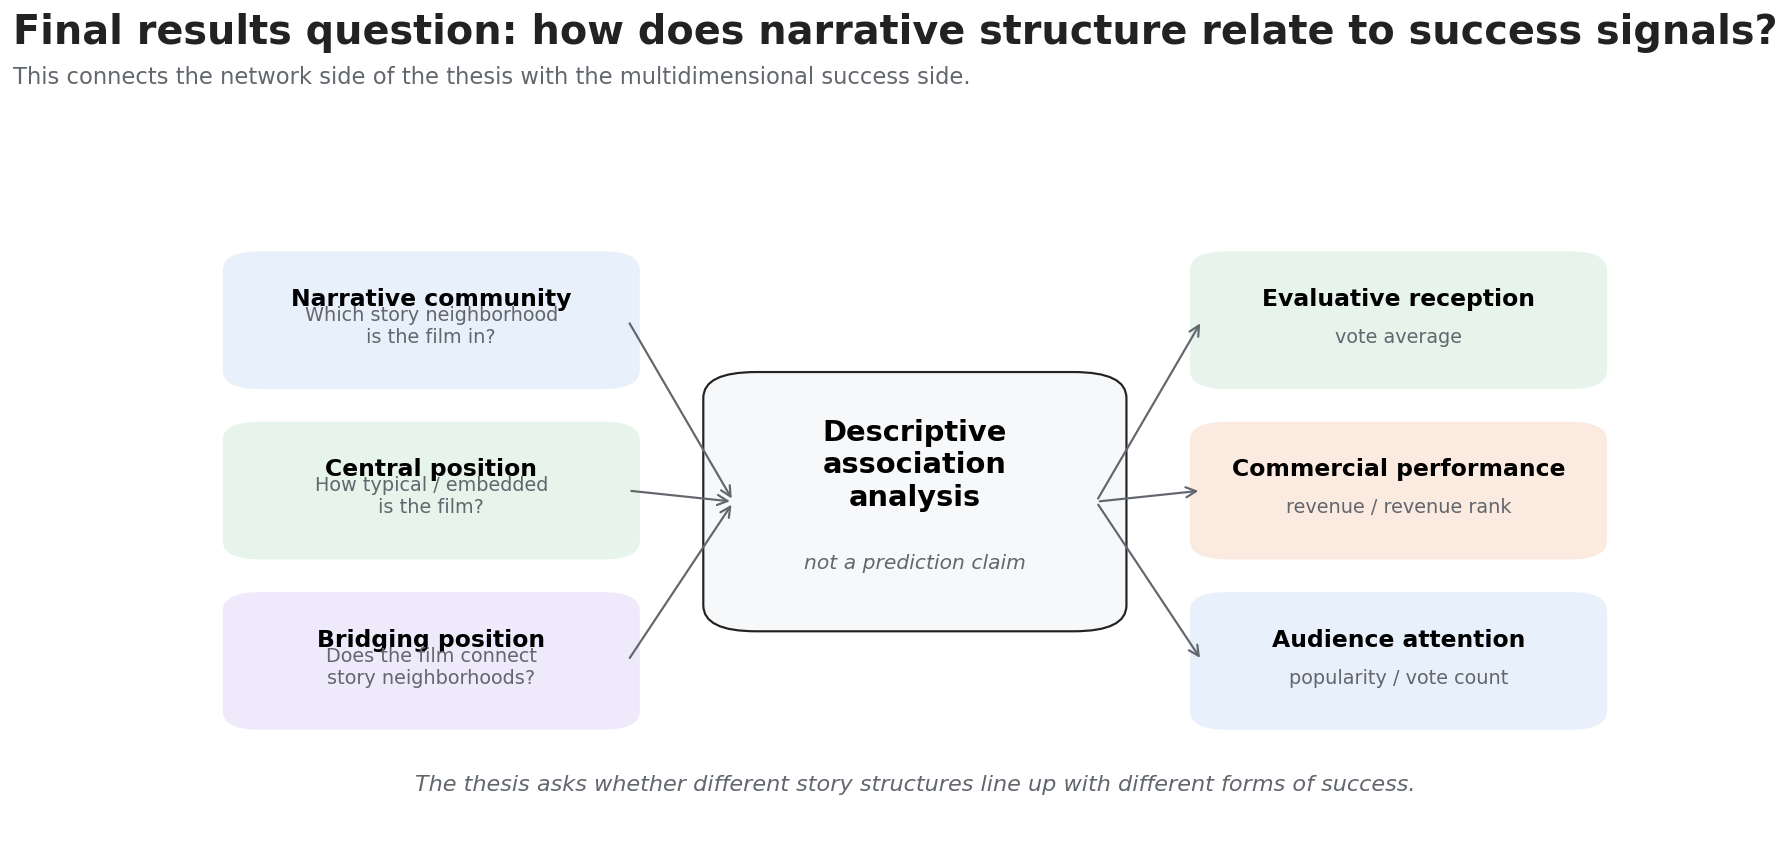

In [4]:

fig, ax = plt.subplots(figsize=(15,7.4))
ax.axis("off"); ax.set_xlim(0,1); ax.set_ylim(0,1)
title_block(fig, "Final results question: how does narrative structure relate to success signals?",
            "This connects the network side of the thesis with the multidimensional success side.")

left = [(.06,.62,"Narrative community","Which story neighborhood\nis the film in?",COL["light_blue"]),
        (.06,.39,"Central position","How typical / embedded\nis the film?",COL["light_green"]),
        (.06,.16,"Bridging position","Does the film connect\nstory neighborhoods?",COL["light_purple"])]
right = [(.70,.62,"Evaluative reception","vote average",COL["light_green"]),
         (.70,.39,"Commercial performance","revenue / revenue rank",COL["light_orange"]),
         (.70,.16,"Audience attention","popularity / vote count",COL["light_blue"])]
for x,y,h,b,bg in left+right:
    ax.add_patch(FancyBboxPatch((x,y),.24,.15,boxstyle="round,pad=.018,rounding_size=.025",facecolor=bg,edgecolor="none"))
    ax.text(x+.12,y+.095,h,ha="center",fontsize=13,fontweight="bold")
    ax.text(x+.12,y+.045,b,ha="center",fontsize=10.7,color=COL["muted"])
ax.add_patch(FancyBboxPatch((.385,.30),.23,.30,boxstyle="round,pad=.025,rounding_size=.035",facecolor=COL["panel"],edgecolor=COL["ink"],linewidth=1.2))
ax.text(.50,.50,"Descriptive\nassociation\nanalysis",ha="center",va="center",fontsize=16,fontweight="bold")
ax.text(.50,.36,"not a prediction claim",ha="center",fontsize=11.2,color=COL["muted"],style="italic")
for _,y,*_ in left:
    ax.add_patch(FancyArrowPatch((.31,y+.075),(.38,.45),arrowstyle="->",mutation_scale=14,lw=1.2,color=COL["muted"]))
for _,y,*_ in right:
    ax.add_patch(FancyArrowPatch((.62,.45),(.69,y+.075),arrowstyle="->",mutation_scale=14,lw=1.2,color=COL["muted"]))
ax.text(.5,.06,"The thesis asks whether different story structures line up with different forms of success.",
        ha="center",fontsize=12.4,color=COL["muted"],style="italic")
save_fig(fig, "01_structure_success_question_map.png")
plt.show()


## 4. Figures 2–3 — Model summary and improvement

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/tables/02_success_model_summary_data.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/02_success_model_summary.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/02_success_model_summary.svg


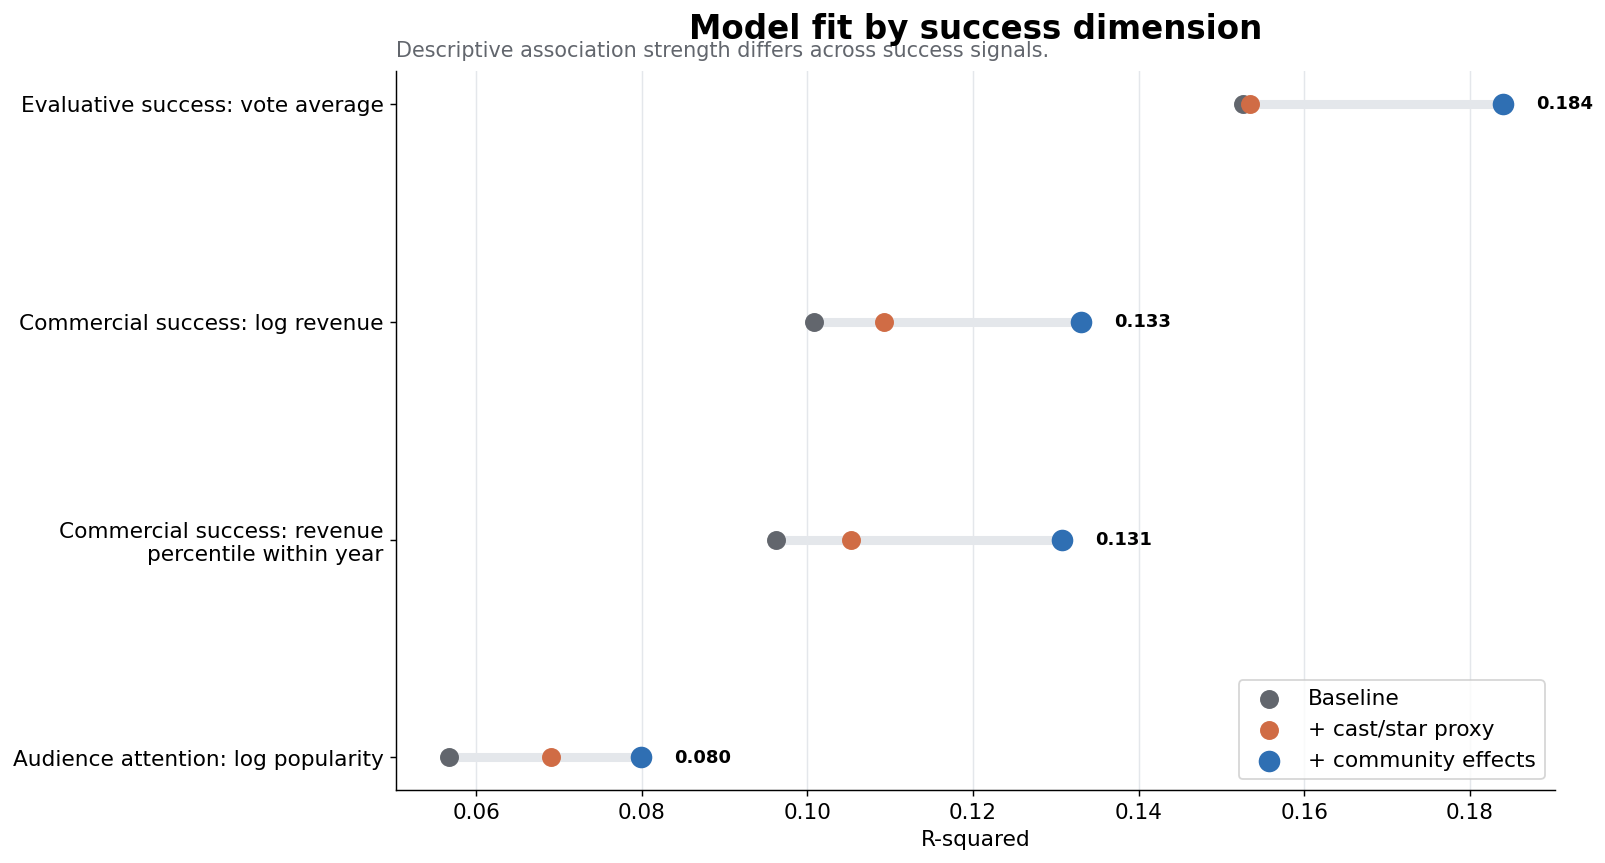

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/tables/03_model_improvement_by_success_dimension_data.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/03_model_improvement_by_success_dimension.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/03_model_improvement_by_success_dimension.svg


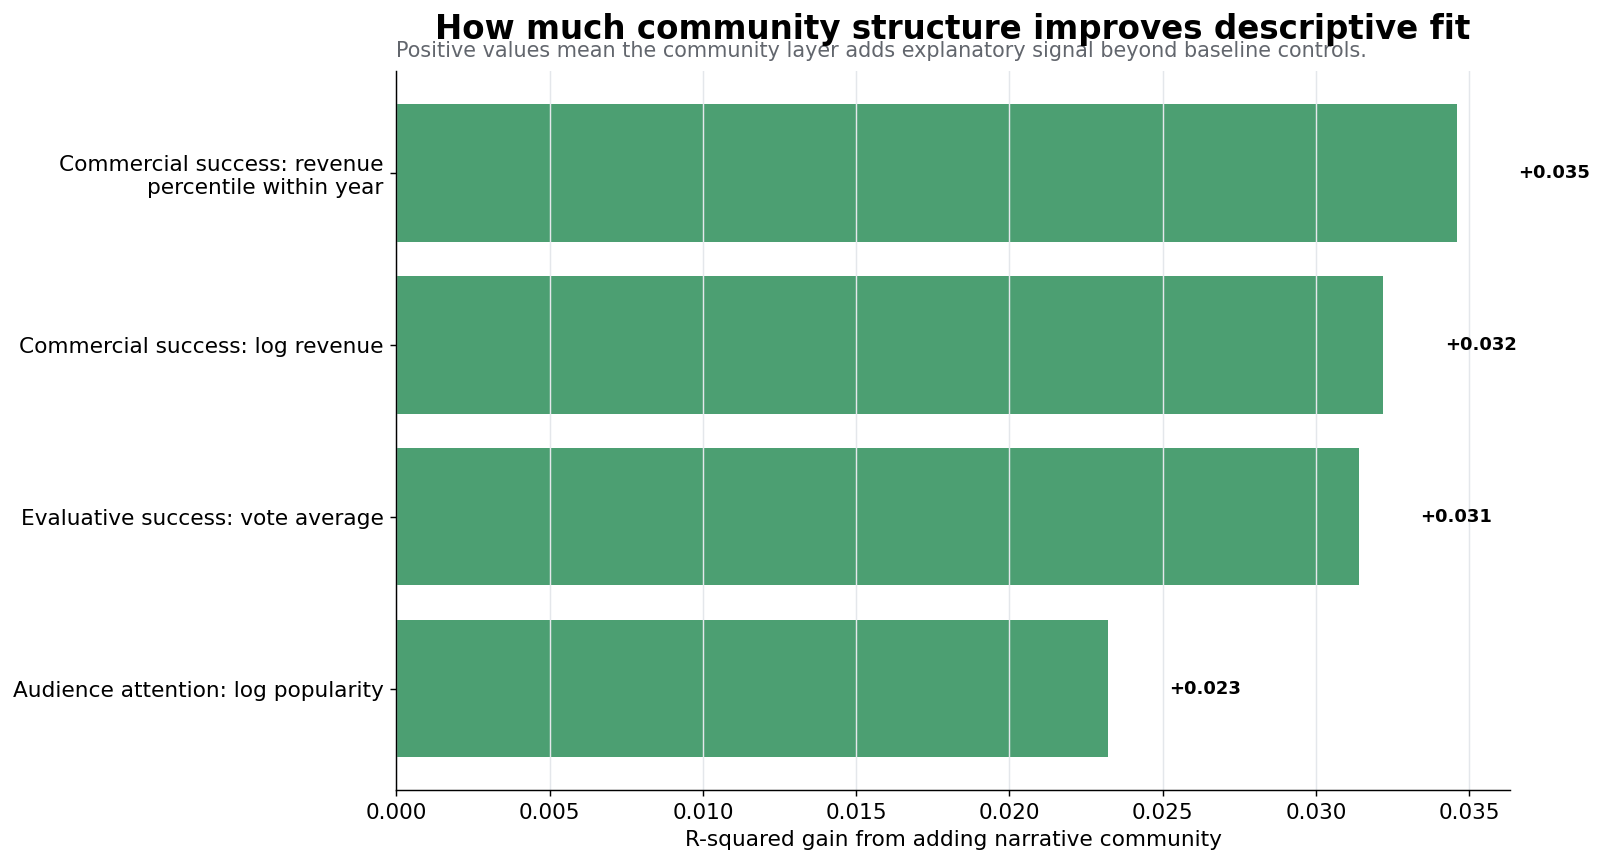

In [5]:

if model_summary is not None and len(model_summary):
    ms = model_summary.copy()
    outcome_col = first_col(ms, ["outcome_label","outcome","dependent_variable"])
    m1 = first_col(ms, ["M1_network_genre_year","model_1","M1"])
    m2 = first_col(ms, ["M2_add_cast_proxy","model_2","M2"])
    m3 = first_col(ms, ["M3_add_community_FE","model_3","M3","best_r2"])
    if outcome_col and m1 and m3:
        ms = ms.sort_values(m3, ascending=True)
        save_table(ms, "02_success_model_summary_data.csv")
        fig, ax = plt.subplots(figsize=(12.5,6.8))
        y=np.arange(len(ms))
        for yi,(_,r) in zip(y,ms.iterrows()):
            ax.plot([r[m1],r[m3]],[yi,yi],color=COL["grid"],lw=5,solid_capstyle="round",zorder=1)
        ax.scatter(ms[m1],y,s=90,color=COL["muted"],label="Baseline",zorder=3)
        if m2: ax.scatter(ms[m2],y,s=90,color=COL["orange"],label="+ cast/star proxy",zorder=3)
        ax.scatter(ms[m3],y,s=120,color=COL["blue"],label="+ community effects",zorder=3)
        for yi,(_,r) in zip(y,ms.iterrows()):
            ax.text(r[m3]+.004,yi,f"{r[m3]:.3f}",va="center",fontsize=10,fontweight="bold")
        ax.set_yticks(y); ax.set_yticklabels([wrap_text(x,34) for x in ms[outcome_col]])
        ax.set_xlabel("R-squared")
        ax.set_title("Model fit by success dimension",pad=18)
        ax.text(0,1.02,"Descriptive association strength differs across success signals.",transform=ax.transAxes,fontsize=11.5,color=COL["muted"])
        ax.spines[["top","right"]].set_visible(False); ax.grid(axis="x",color=COL["grid"]); ax.legend(loc="lower right")
        plt.tight_layout(); save_fig(fig,"02_success_model_summary.png"); plt.show()

        gain=ms.copy()
        gain["community_gain"]=gain[m3]-gain[m1]
        gain=gain.sort_values("community_gain",ascending=True)
        save_table(gain, "03_model_improvement_by_success_dimension_data.csv")
        fig,ax=plt.subplots(figsize=(12.5,6.8))
        y=np.arange(len(gain))
        ax.barh(y,gain["community_gain"],color=COL["green"],alpha=.86)
        for yi,(_,r) in zip(y,gain.iterrows()):
            ax.text(r["community_gain"]+.002,yi,f"+{r['community_gain']:.3f}",va="center",fontsize=10,fontweight="bold")
        ax.set_yticks(y); ax.set_yticklabels([wrap_text(x,34) for x in gain[outcome_col]])
        ax.set_xlabel("R-squared gain from adding narrative community")
        ax.set_title("How much community structure improves descriptive fit",pad=18)
        ax.text(0,1.02,"Positive values mean the community layer adds explanatory signal beyond baseline controls.",transform=ax.transAxes,fontsize=11.5,color=COL["muted"])
        ax.spines[["top","right"]].set_visible(False); ax.grid(axis="x",color=COL["grid"])
        plt.tight_layout(); save_fig(fig,"03_model_improvement_by_success_dimension.png"); plt.show()
    else:
        print("Model summary columns not detected.")
else:
    print("No model summary table found.")


## 5. Figure 4 — Community success profile heatmap

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/tables/04_community_success_profile_heatmap_data.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/tables/04_community_success_profile_heatmap_zscores.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/04_community_success_profile_heatmap.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/04_community_success_profile_heatmap.svg


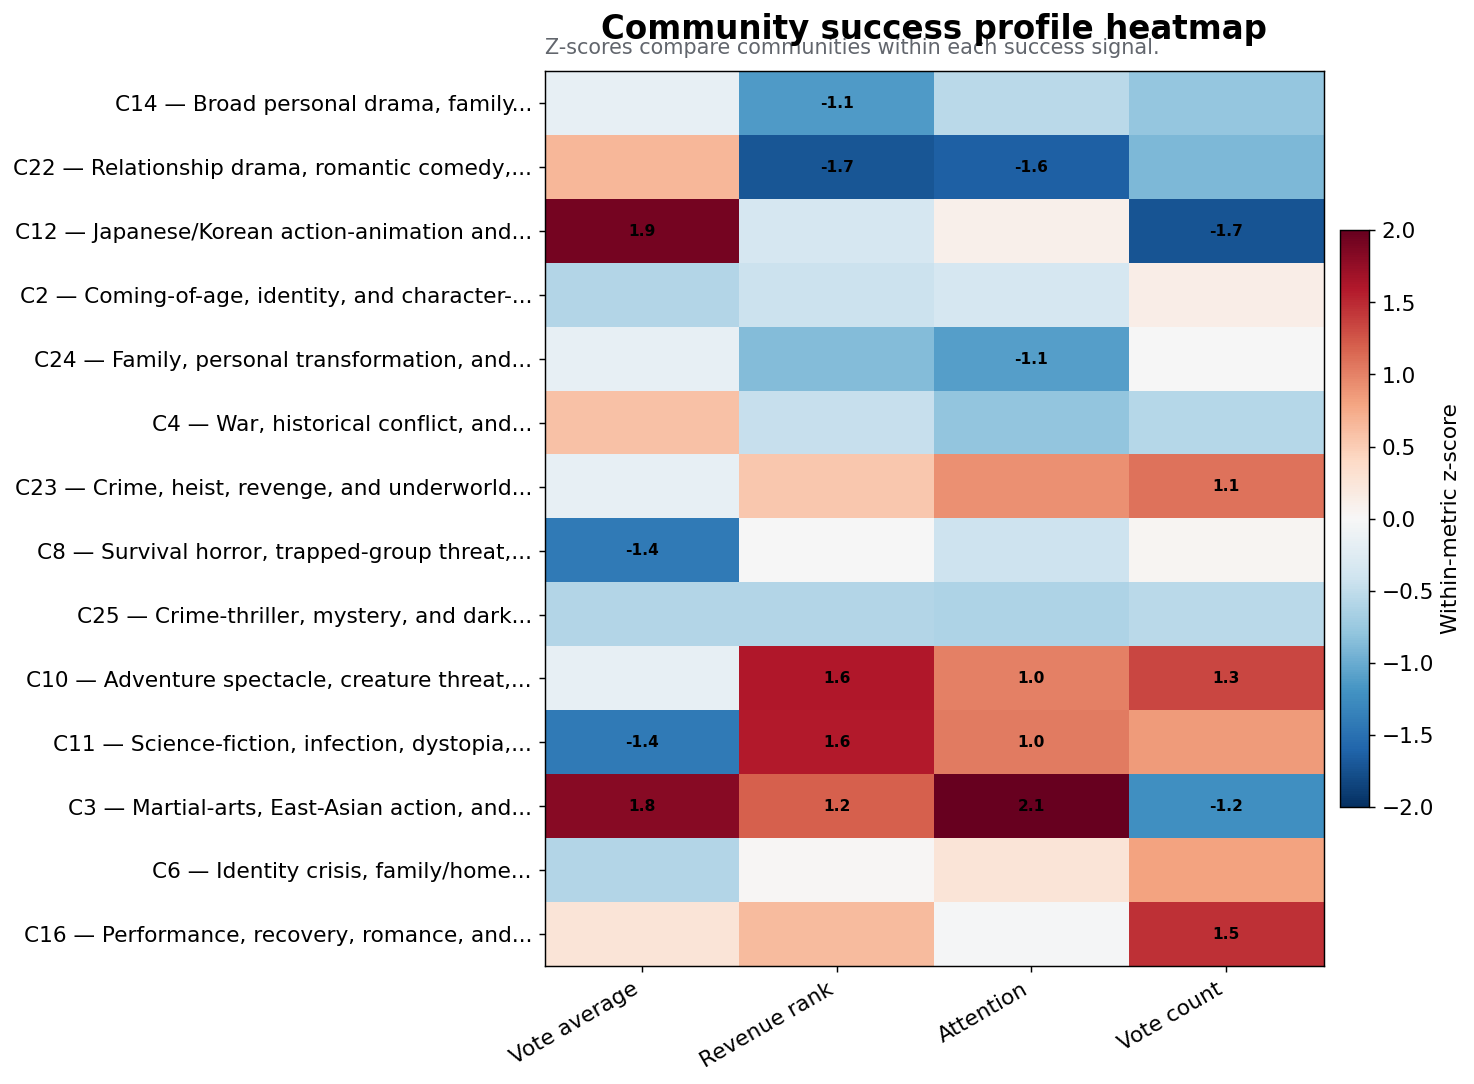

In [6]:

if community_success is not None and len(community_success):
    cs=community_success.copy()
    metrics=[("Vote average", first_col(cs,["median_vote_average","vote_average_median","mean_vote_average"])),
             ("Revenue rank", first_col(cs,["median_revenue_percentile_year","median_revenue_percentile","revenue_percentile_year_median"])),
             ("Revenue", first_col(cs,["median_log_revenue","mean_log_revenue","log_revenue_median"])),
             ("Attention", first_col(cs,["median_log_popularity","median_popularity","mean_log_popularity","popularity_median"])),
             ("Vote count", first_col(cs,["median_vote_count","vote_count_median"]))]
    metrics=[m for m in metrics if m[1]]
    n_col=first_col(cs,["n_films","n_nodes","n"])
    if metrics:
        cs_plot=cs.sort_values(n_col,ascending=False).head(14).copy() if n_col else cs.head(14).copy()
        heat=pd.DataFrame(index=[f"C{int(c)}" for c in cs_plot["community_id"]])
        for name,col in metrics:
            heat[name]=zscore(cs_plot[col]).values
        save_table(cs_plot,"04_community_success_profile_heatmap_data.csv")
        save_table(heat.reset_index().rename(columns={"index":"community"}),"04_community_success_profile_heatmap_zscores.csv")
        fig,ax=plt.subplots(figsize=(11.5,8.5))
        im=ax.imshow(heat.values,aspect="auto",cmap="RdBu_r",vmin=-2,vmax=2)
        ax.set_xticks(np.arange(len(heat.columns))); ax.set_xticklabels(heat.columns,rotation=30,ha="right")
        ylabels=[f"C{int(r.community_id)} — {shorten(r.get('narrative_label',''),42)}" for _,r in cs_plot.iterrows()]
        ax.set_yticks(np.arange(len(heat.index))); ax.set_yticklabels(ylabels)
        for i in range(heat.shape[0]):
            for j in range(heat.shape[1]):
                val=heat.iloc[i,j]
                if pd.notna(val) and abs(val)>=1.0:
                    ax.text(j,i,f"{val:.1f}",ha="center",va="center",fontsize=8.5,fontweight="bold")
        ax.set_title("Community success profile heatmap",pad=18)
        ax.text(0,1.02,"Z-scores compare communities within each success signal.",transform=ax.transAxes,fontsize=11.5,color=COL["muted"])
        cbar=plt.colorbar(im,ax=ax,fraction=.035,pad=.02); cbar.set_label("Within-metric z-score")
        plt.tight_layout(); save_fig(fig,"04_community_success_profile_heatmap.png"); plt.show()
    else:
        print("No usable community success metrics.")
else:
    print("No community success table found.")


## 6. Figures 5–6 — Ranked communities by success signal

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/tables/05_top_communities_by_evaluative_success_data.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/05_top_communities_by_evaluative_success.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/05_top_communities_by_evaluative_success.svg


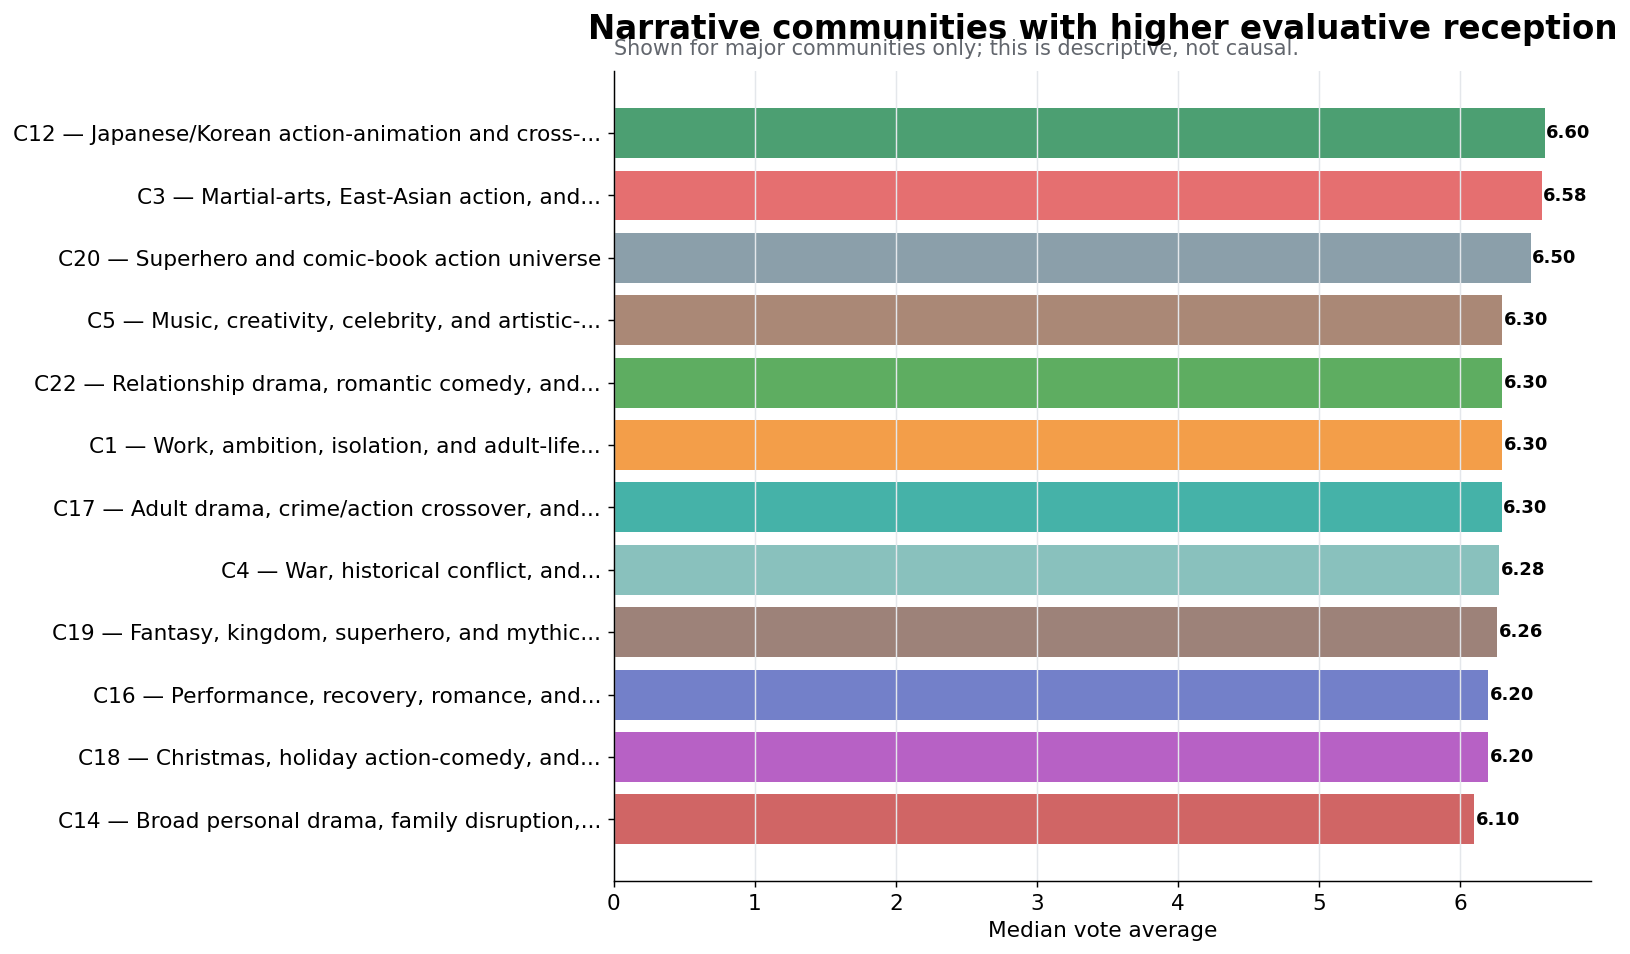

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/tables/06_top_communities_by_commercial_success_data.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/06_top_communities_by_commercial_success.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/06_top_communities_by_commercial_success.svg


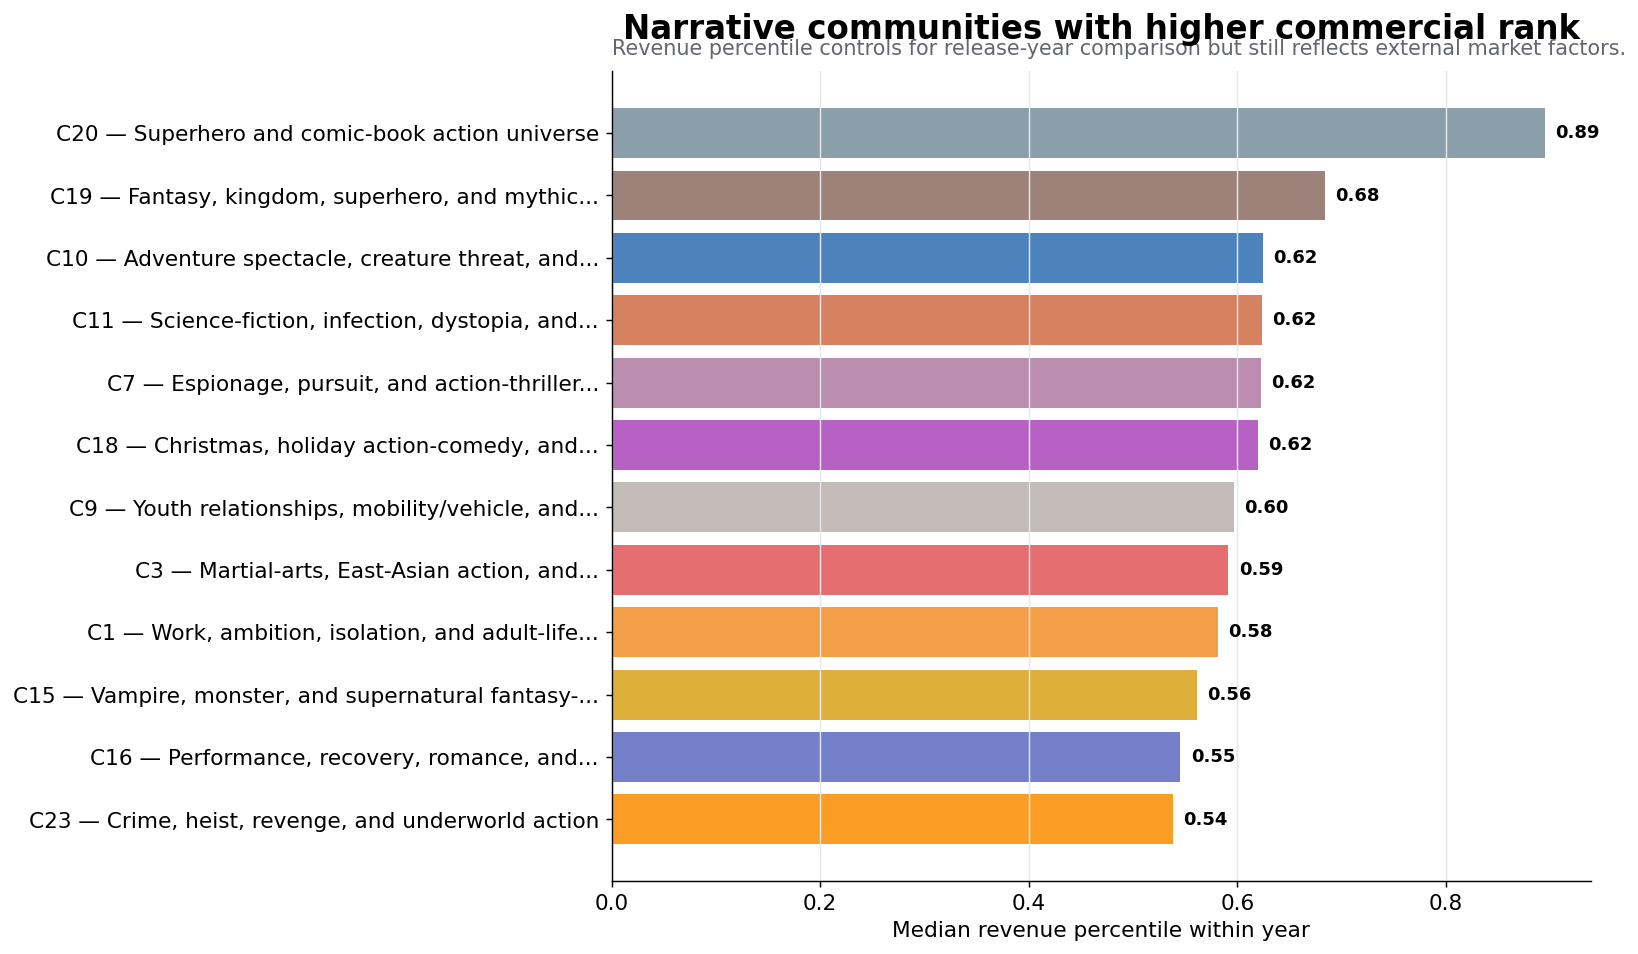

In [7]:

def ranked_community_plot(metric_col, title, subtitle, xlabel, filename, color_base):
    if community_success is None or metric_col is None:
        print("Missing data for", filename); return
    cs=community_success.copy()
    n_col=first_col(cs,["n_films","n_nodes","n"])
    if n_col: cs=cs[cs[n_col]>=100]
    tmp=cs.dropna(subset=[metric_col]).sort_values(metric_col,ascending=True).tail(12)
    if len(tmp)==0: return
    save_table(tmp, filename.replace(".png","_data.csv"))
    fig,ax=plt.subplots(figsize=(12.5,7.5))
    labels=[f"C{int(r.community_id)} — {shorten(r.get('narrative_label',''),46)}" for _,r in tmp.iterrows()]
    colors=[community_color(c) for c in tmp["community_id"]]
    ax.barh(labels,tmp[metric_col],color=colors,alpha=.86)
    for i,(_,r) in enumerate(tmp.iterrows()):
        ax.text(r[metric_col]+0.01,i,f"{r[metric_col]:.2f}",va="center",fontweight="bold",fontsize=10)
    ax.set_title(title,pad=18)
    ax.text(0,1.02,subtitle,transform=ax.transAxes,fontsize=11.5,color=COL["muted"])
    ax.set_xlabel(xlabel); ax.spines[["top","right"]].set_visible(False); ax.grid(axis="x",color=COL["grid"])
    plt.tight_layout(); save_fig(fig,filename); plt.show()

if community_success is not None:
    eval_metric=first_col(community_success,["median_vote_average","vote_average_median","mean_vote_average"])
    comm_metric=first_col(community_success,["median_revenue_percentile_year","median_revenue_percentile","revenue_percentile_year_median","mean_revenue_percentile_year"])
    ranked_community_plot(eval_metric,"Narrative communities with higher evaluative reception",
                          "Shown for major communities only; this is descriptive, not causal.",
                          "Median vote average","05_top_communities_by_evaluative_success.png",COL["green"])
    ranked_community_plot(comm_metric,"Narrative communities with higher commercial rank",
                          "Revenue percentile controls for release-year comparison but still reflects external market factors.",
                          "Median revenue percentile within year","06_top_communities_by_commercial_success.png",COL["orange"])


## 7. Figures 7–8 — Centrality/bridging success profiles

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/tables/07_centrality_success_profile_data.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/07_centrality_success_profile.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/07_centrality_success_profile.svg


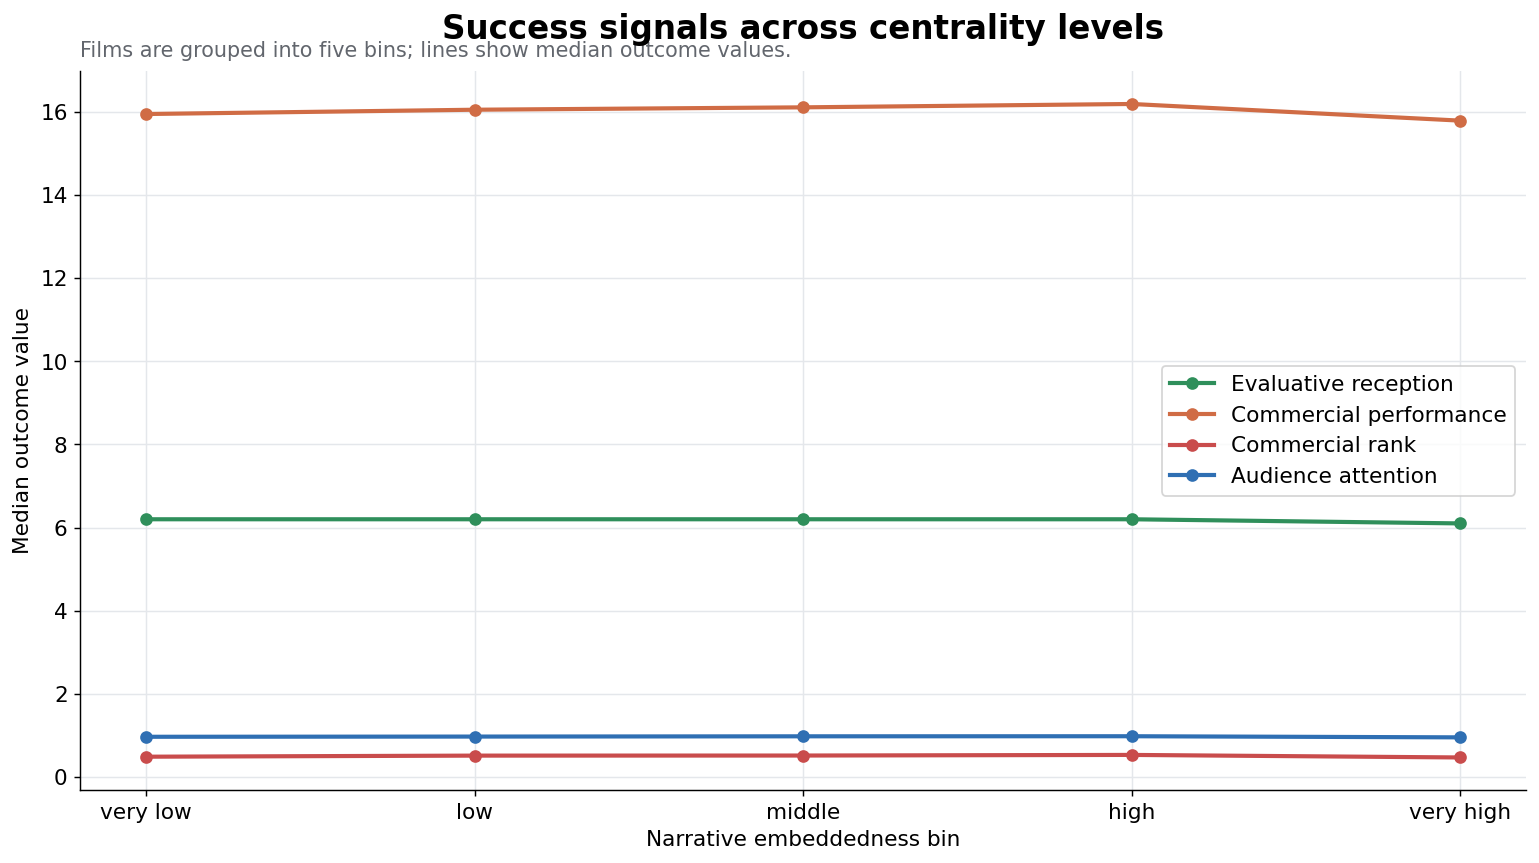

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/tables/08_bridging_success_profile_data.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/08_bridging_success_profile.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/08_bridging_success_profile.svg


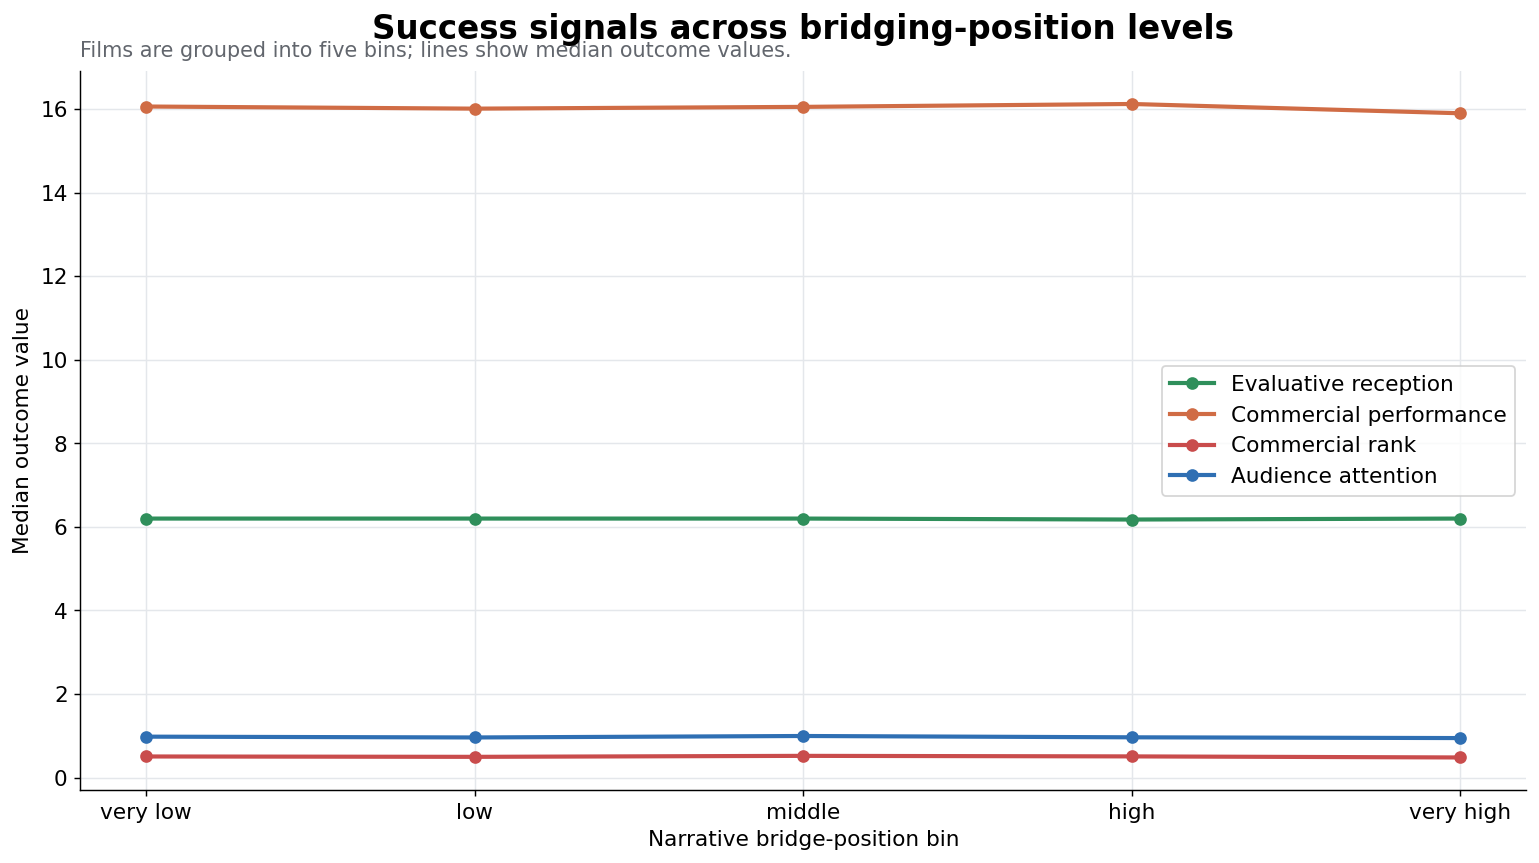

In [8]:

def binned_profile(score_col, bin_col_name, filename, title, xlabel):
    if score_col is None or not outcomes:
        print("Missing score/outcomes for", filename); return
    temp=df.dropna(subset=[score_col]).copy()
    temp[bin_col_name]=pd.qcut(temp[score_col].rank(method="first"),q=5,labels=["very low","low","middle","high","very high"])
    rows=[]
    for outcome_label,col,color in outcomes:
        if col in temp.columns:
            g=temp.dropna(subset=[col]).groupby(bin_col_name,observed=True)[col].median().reset_index()
            g["outcome"]=outcome_label; g["color"]=color
            rows.append(g.rename(columns={col:"median_value"}))
    prof=pd.concat(rows,ignore_index=True) if rows else pd.DataFrame()
    save_table(prof, filename.replace(".png","_data.csv"))
    if len(prof)==0: return
    fig,ax=plt.subplots(figsize=(12,6.8))
    order=["very low","low","middle","high","very high"]
    for outcome_label,col,color in outcomes:
        sub=prof[prof["outcome"]==outcome_label]
        if len(sub):
            sub=sub.set_index(bin_col_name).reindex(order).reset_index()
            ax.plot(order,sub["median_value"],marker="o",lw=2.3,color=color,label=outcome_label)
    ax.set_title(title,pad=18)
    ax.text(0,1.02,"Films are grouped into five bins; lines show median outcome values.",transform=ax.transAxes,fontsize=11.5,color=COL["muted"])
    ax.set_xlabel(xlabel); ax.set_ylabel("Median outcome value")
    ax.spines[["top","right"]].set_visible(False); ax.grid(color=COL["grid"]); ax.legend()
    plt.tight_layout(); save_fig(fig,filename); plt.show()

binned_profile(weighted_degree,"centrality_bin","07_centrality_success_profile.png",
               "Success signals across centrality levels","Narrative embeddedness bin")
binned_profile(betweenness,"bridging_bin","08_bridging_success_profile.png",
               "Success signals across bridging-position levels","Narrative bridge-position bin")


## 8. Figures 9–10 — Result interpretation and final storyline

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/09_key_result_interpretation_cards.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/09_key_result_interpretation_cards.svg


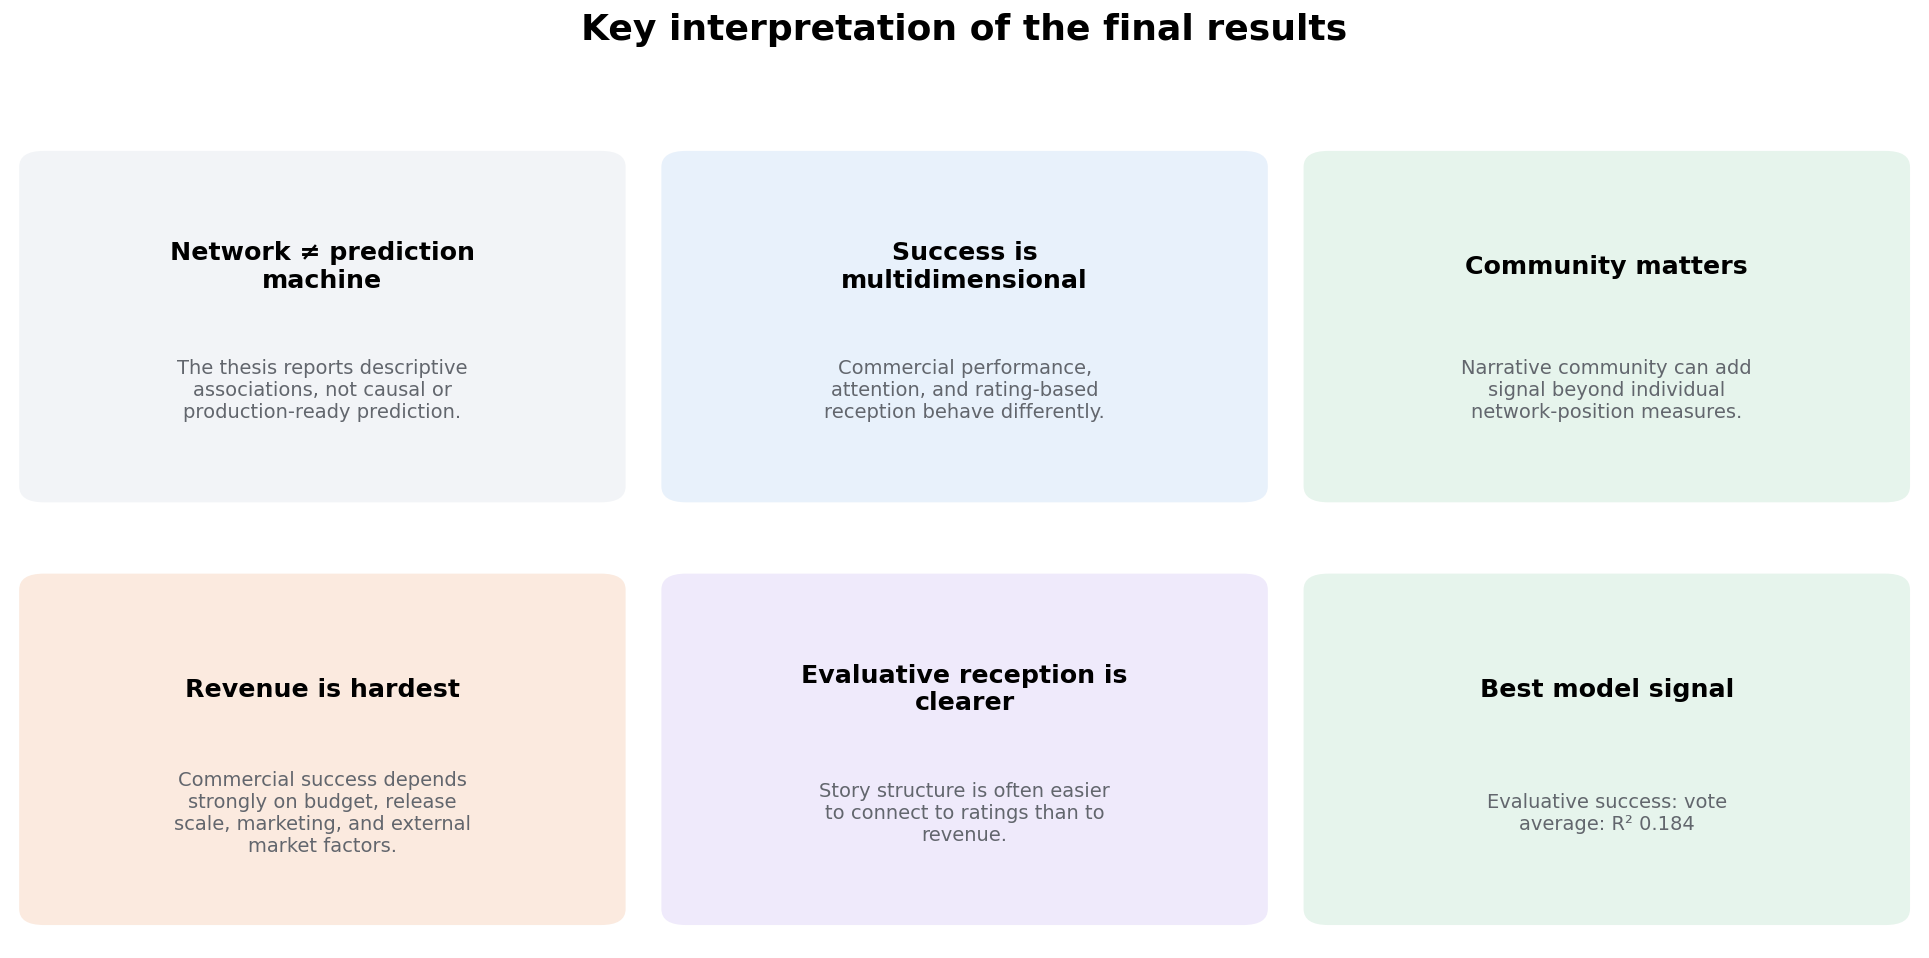

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/10_final_results_storyline.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/10_final_results_storyline.svg


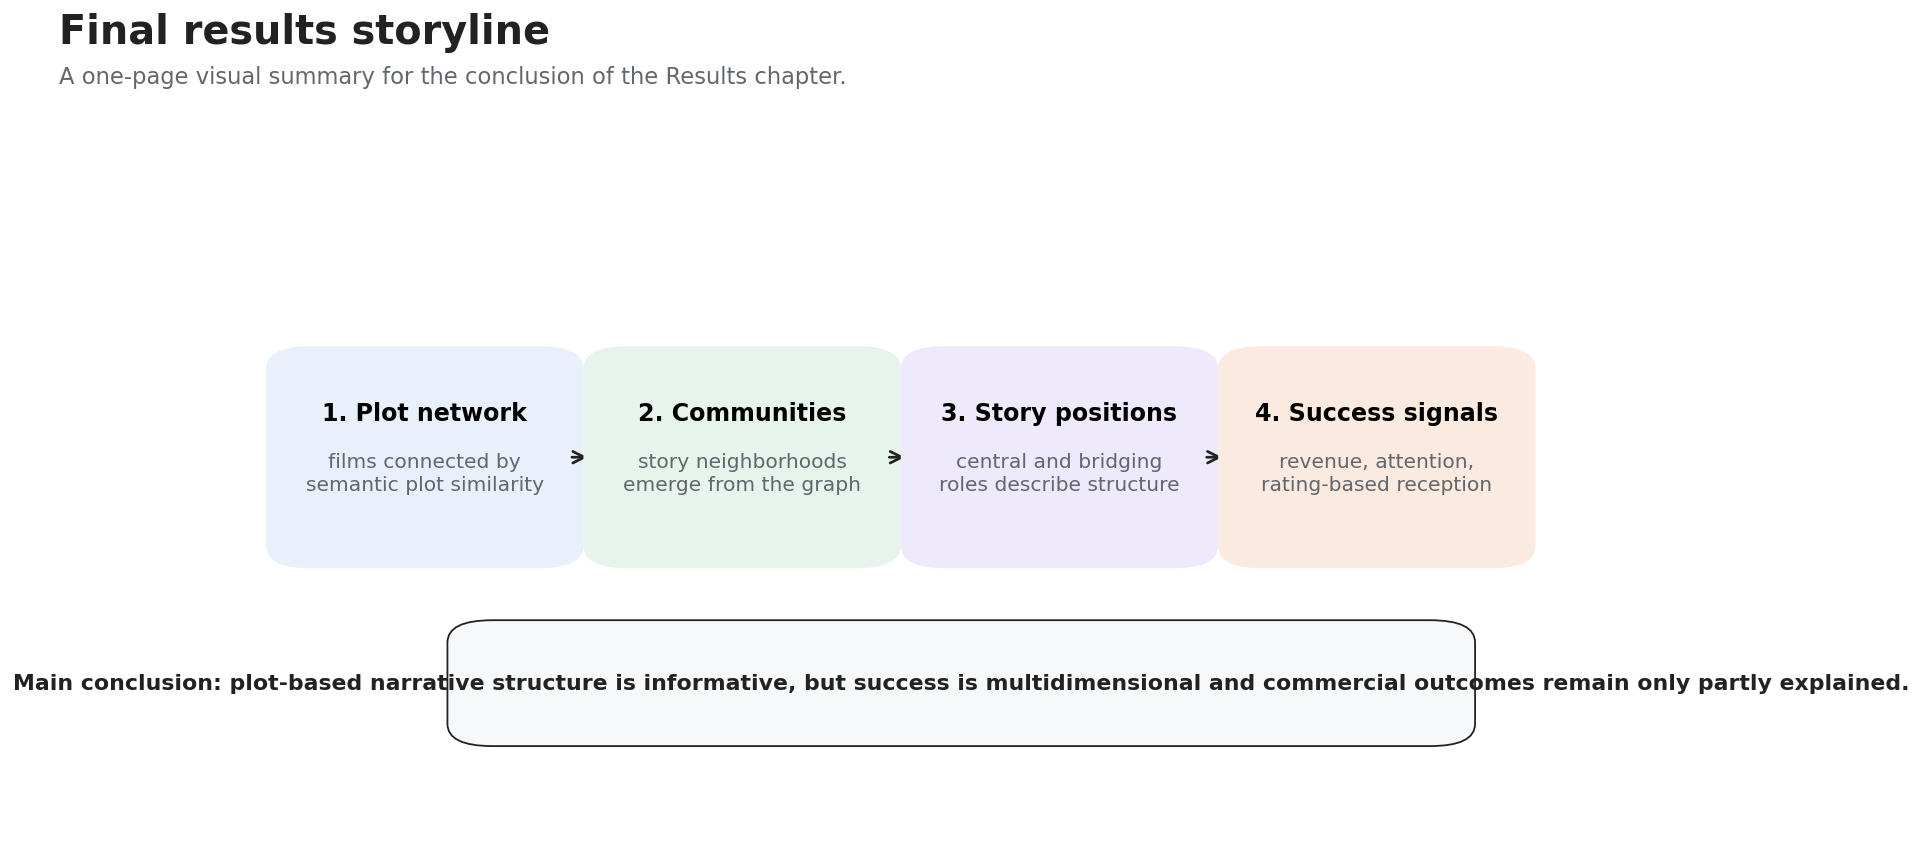

In [9]:

# Figure 9
best_outcome = None
best_r2 = None
if model_summary is not None and len(model_summary):
    oc = first_col(model_summary,["outcome_label","outcome","dependent_variable"])
    bc = first_col(model_summary,["M3_add_community_FE","model_3","M3","best_r2"])
    if oc and bc:
        row = model_summary.sort_values(bc, ascending=False).iloc[0]
        best_outcome, best_r2 = row[oc], row[bc]

cards=[
    ("Network ≠ prediction machine","The thesis reports descriptive associations, not causal or production-ready prediction.",COL["light_gray"]),
    ("Success is multidimensional","Commercial performance, attention, and rating-based reception behave differently.",COL["light_blue"]),
    ("Community matters","Narrative community can add signal beyond individual network-position measures.",COL["light_green"]),
    ("Revenue is hardest","Commercial success depends strongly on budget, release scale, marketing, and external market factors.",COL["light_orange"]),
    ("Evaluative reception is clearer","Story structure is often easier to connect to ratings than to revenue.",COL["light_purple"]),
    ("Best model signal",f"{shorten(str(best_outcome),44)}: R² {best_r2:.3f}" if best_outcome is not None else "Check final model summary table.",COL["light_green"]),
]
fig,axes=plt.subplots(2,3,figsize=(15,7.5)); axes=axes.ravel()
for ax,(h,b,bg) in zip(axes,cards):
    ax.axis("off")
    ax.add_patch(FancyBboxPatch((.04,.08),.92,.82,boxstyle="round,pad=.03,rounding_size=.04",facecolor=bg,edgecolor="none"))
    ax.text(.5,.64,wrap_text(h,24),ha="center",va="center",fontsize=14,fontweight="bold")
    ax.text(.5,.33,wrap_text(b,32),ha="center",va="center",fontsize=10.8,color=COL["muted"])
fig.suptitle("Key interpretation of the final results",fontsize=20,fontweight="bold",y=.98)
plt.tight_layout(rect=[0,0,1,.95]); save_fig(fig,"09_key_result_interpretation_cards.png"); plt.show()

# Figure 10
fig,ax=plt.subplots(figsize=(15,7.4)); ax.axis("off"); ax.set_xlim(0,1); ax.set_ylim(0,1)
title_block(fig,"Final results storyline","A one-page visual summary for the conclusion of the Results chapter.")
steps=[(.06,"1. Plot network","films connected by\nsemantic plot similarity",COL["light_blue"]),
       (.27,"2. Communities","story neighborhoods\nemerge from the graph",COL["light_green"]),
       (.48,"3. Story positions","central and bridging\nroles describe structure",COL["light_purple"]),
       (.69,"4. Success signals","revenue, attention,\nrating-based reception",COL["light_orange"])]
for i,(x,h,b,bg) in enumerate(steps):
    ax.add_patch(FancyBboxPatch((x,.38),.17,.26,boxstyle="round,pad=.02,rounding_size=.03",facecolor=bg,edgecolor="none"))
    ax.text(x+.085,.56,h,ha="center",fontsize=13.2,fontweight="bold")
    ax.text(x+.085,.465,b,ha="center",fontsize=11.2,color=COL["muted"],linespacing=1.25)
    if i<len(steps)-1:
        ax.add_patch(FancyArrowPatch((x+.18,.51),(steps[i+1][0]-.015,.51),arrowstyle="->",mutation_scale=16,lw=1.5,color=COL["ink"]))
ax.add_patch(FancyBboxPatch((.18,.14),.64,.13,boxstyle="round,pad=.02,rounding_size=.03",facecolor=COL["panel"],edgecolor=COL["ink"],linewidth=1))
ax.text(.5,.205,"Main conclusion: plot-based narrative structure is informative, but success is multidimensional and commercial outcomes remain only partly explained.",
        ha="center",va="center",fontsize=12.2,color=COL["ink"],fontweight="bold")
save_fig(fig,"10_final_results_storyline.png"); plt.show()


## 9. Export interpretation note

In [10]:

note = """
Brick 8 — Narrative structure and success signals interpretation note

This is the final results brick.

Main message:
The thesis does not claim to predict movie success. It shows that plot-based narrative structure is descriptively associated with different success signals. Narrative communities and network positions appear more informative for some forms of success, especially rating-based evaluative reception, than for purely commercial outcomes.

Recommended main thesis figures:
1. 01_structure_success_question_map.png
2. 02_success_model_summary.png
3. 03_model_improvement_by_success_dimension.png
4. 04_community_success_profile_heatmap.png
5. 05_top_communities_by_evaluative_success.png
6. 06_top_communities_by_commercial_success.png
7. 09_key_result_interpretation_cards.png
8. 10_final_results_storyline.png

Recommended appendix/supporting figures:
1. 07_centrality_success_profile.png
2. 08_bridging_success_profile.png

Important wording:
Use “descriptive association,” “success signals,” and “multidimensional success.” Avoid overclaiming prediction, causality, or universal success formulas.
""".strip()
write_text(note, "brick_08_interpretation_note.txt")
print(note)

print("\nFigures:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("-", p.name)
print("\nTables:")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print("-", p.name)


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/text/brick_08_interpretation_note.txt
Brick 8 — Narrative structure and success signals interpretation note

This is the final results brick.

Main message:
The thesis does not claim to predict movie success. It shows that plot-based narrative structure is descriptively associated with different success signals. Narrative communities and network positions appear more informative for some forms of success, especially rating-based evaluative reception, than for purely commercial outcomes.

Recommended main thesis figures:
1. 01_structure_success_question_map.png
2. 02_success_model_summary.png
3. 03_model_improvement_by_success_dimension.png
4. 04_community_success_profile_heatmap.png
5. 05_top_communities_by_evaluative_success.png
6. 06_top_communities_by_commercial_success.png
7. 09_key_result_interpretation_cards.png
8. 10_final_results_storyline.png

Recommended appendix/supporting figures:
